# Daraz BD market intelligence EDA

This is Phase 4 of the pipeline project. Everything here reads straight from the `clean_products` table in Neon, after all 7 batches were loaded by the GitHub Actions run.

Rules I set before looking at the numbers:
- Nulls stay as they are. I do not fill or guess missing ratings.
- Medians for prices, never means. A mean price across laptops and sunglasses only tells me the product mix.
- Every rating based number shows its product count (n) next to it.
- Discount depth is averaged among discounted products only, because non discounted products are stored as 0.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sqlalchemy import create_engine

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

In [2]:
# the .env lives in the pipeline folder
load_dotenv("../pipeline/.env")
engine = create_engine(os.getenv("NEON_CONNECTION_STRING"))
df = pd.read_sql("SELECT * FROM clean_products", engine)

In [3]:
# In the raw data "rating" held the review count and "seller_rating" held the star value.
# I rename them here so the code below reads the way it sounds.
num_cols = ["price", "original_price", "discount_perc", "positive_seller_ratings",
            "ship_on_time", "seller_rating", "rating", "category_match_score"]
df[num_cols] = df[num_cols].apply(pd.to_numeric, errors="coerce")
df = df.rename(columns={"rating": "reviews", "seller_rating": "stars"})
df.shape

(8252, 26)

## 1. What counts as a rated product?

Before comparing anything, I want to know how many products really have a rating. Reviews and stars are blank for most rows, which is real (no reviews yet), so I leave them blank. The thing to check is whether some rows carry a fake looking value instead of a blank.

In [4]:
print("rows:", len(df), "| flagged as contamination:", int(df["is_contamination_flagged"].sum()))
print("reviews missing:", int(df["reviews"].isna().sum()), "| stars missing:", int(df["stars"].isna().sum()))

zero_zero = (df["reviews"] == 0) & (df["stars"] == 0)
print("rows with 0 reviews AND 0 stars:", int(zero_zero.sum()))

# a real rating means at least one review and a star value above 0
df["has_reviews"] = (df["reviews"] >= 1) & (df["stars"] > 0)
print("rows with a real rating:", int(df["has_reviews"].sum()), f"({df['has_reviews'].mean()*100:.1f}% of all rows)")

rows: 8252 | flagged as contamination: 1650
reviews missing: 7249 | stars missing: 7251
rows with 0 reviews AND 0 stars: 272
rows with a real rating: 729 (8.8% of all rows)


**What I found:** 8,252 rows, but only **729 (8.8%)** have a real rating. Another **272 rows** show 0 reviews and 0 stars. They are not ratings. They are products with no reviews yet, stored as 0 instead of blank. The other 7,249 unrated rows are simply blank. Two more rows have a review count but no star value, and they stay unrated.

**Why it matters:** if I counted every row where the review count is not blank, I would get about 1,000 rated products and overstate coverage by 272 rows. Every rated number below uses `has_reviews` (at least 1 review and stars above 0). I do not know why Daraz shows a 0 for some unrated products and leaves others blank, so I treat both as unrated. The "about 12% rated" figure I had planned for page 2 was this overcount, and the Power BI card has to apply the same rule.

## 2. Should the 1,650 flagged rows stay in?

The pipeline flags rows whose text does not match their category (a phone case sitting in Laptops). It does not delete them. My rule from the start: compute the key stats both ways. If they barely differ, I exclude the flagged rows and say so. If they differ a lot, that difference is a finding in itself.

In [5]:
def summarize(d):
    g = d.groupby("category_normalized")
    out = pd.DataFrame({
        "n": g.size(),
        "median_price": g["price"].median(),
        "discounted_pct": g["is_discounted"].mean() * 100,
        "rated_n": g["has_reviews"].sum(),
    })
    out["median_depth"] = d[d["is_discounted"]].groupby("category_normalized")["discount_perc"].median()
    return out

all_rows = summarize(df)
unflagged = summarize(df[~df["is_contamination_flagged"]])

cmp = all_rows.join(unflagged, lsuffix="_all", rsuffix="_clean")
cmp["price_change_pct"] = (cmp["median_price_clean"] / cmp["median_price_all"] - 1) * 100
cmp = cmp.sort_values("price_change_pct", key=abs, ascending=False)
show = ["n_all", "n_clean", "median_price_all", "median_price_clean", "price_change_pct",
        "discounted_pct_all", "discounted_pct_clean", "median_depth_all", "median_depth_clean"]
print(cmp[show].round(1).to_string())

print("\nMedian price of the flagged rows themselves:")
print(df[df["is_contamination_flagged"]].groupby("category_normalized")["price"].median().round(0).to_string())

                     n_all  n_clean  median_price_all  median_price_clean  price_change_pct  discounted_pct_all  discounted_pct_clean  median_depth_all  median_depth_clean
category_normalized                                                                                                                                                        
Televisions            395      226           17200.0             32250.0              87.5                72.2                  53.1              36.0                21.0
Laptops                484      283           58550.0             76600.0              30.8                75.8                  65.4              12.0                 6.0
Refrigerators          598      448           31499.5             38907.0              23.5                67.4                  61.8              40.0                28.0
Books                  998      761             320.0               290.0              -9.4                88.8                  89.6       

**What I found:** the flagged rows barely matter for most categories, but they matter a lot for the big ticket ones. Excluding them moves the median price of **Televisions by +87.5%** (17,200 to 32,250 Taka), **Laptops by +30.8%** and **Refrigerators by +23.5%**. Every other category moves by less than 10%. The flagged rows in those three have median prices of 369 (Televisions), 509 (Laptops) and 522 (Refrigerators) Taka, so they are priced like small accessories, not like the product. Discount numbers move too: Televisions go from 72.2% discounted to 53.1% once the flagged rows are out.

**Why it matters:** the difference is large in some categories, so I treat it as a finding, not a rounding issue. Leaving the flagged rows in would make a TV look like a 17,200 Taka product when the real middle is 32,250. I exclude all flagged rows from every analysis below. For the README, the contamination check is what makes the price numbers credible.

In [6]:
clean = df[~df["is_contamination_flagged"]].copy()
print("rows kept after excluding flagged:", len(clean))

rows kept after excluding flagged: 6602


## 3. Accessories: do they skew the price stats?

The contamination check catches products from the wrong category. It does not catch a real accessory that belongs to the category, like an AC cover or a fridge door lock. Those are legitimate listings, but they cost a few hundred Taka next to a 50,000 Taka AC, so they could drag a category median down.

To spot accessories I use `category_leaf`, which is the last part of Daraz's breadcrumb (for example `Home Appliances > Cooling > Air Conditioning` has the leaf "Air Conditioning"). Inside a category I take the most common leaf as the main product and treat every other leaf as an accessory. In Air Conditioners, 270 rows have the leaf "Air Conditioning" (median 68,584 Taka) and 100 rows have "Appliances Parts & Accessories" (median 484 Taka), so the second group is clearly covers and sprays, not ACs.

I only use this rule in hardware categories, where one main product is clear. In categories like Toys or Sunglasses the leaves are mixed but all legitimate (dolls, puzzles and cars are all toys), so the rule would wrongly cut more than half of the good rows.

In [7]:
HARDWARE = ["Air Conditioners", "Refrigerators", "Keyboards", "Hard Drives",
            "Kitchen Appliances", "Televisions", "Laptops"]

main_leaf = clean.groupby("category_normalized")["category_leaf"].agg(lambda s: s.value_counts().idxmax())
clean["is_accessory"] = (
    clean["category_normalized"].isin(HARDWARE)
    & (clean["category_leaf"] != clean["category_normalized"].map(main_leaf))
)

rows = []
for cat in HARDWARE:
    x = clean[clean["category_normalized"] == cat]
    rows.append({
        "category": cat,
        "main_leaf": main_leaf[cat],
        "accessory_pct": x["is_accessory"].mean() * 100,
        "median_all": x["price"].median(),
        "median_main_only": x.loc[~x["is_accessory"], "price"].median(),
    })
acc = pd.DataFrame(rows).set_index("category")
acc["change_pct"] = (acc["median_main_only"] / acc["median_all"] - 1) * 100
print(acc.round(1).sort_values("change_pct", ascending=False).to_string())

print("\nA few rows the rule marks as accessories:")
for cat in ["Air Conditioners", "Refrigerators"]:
    x = clean[(clean["category_normalized"] == cat) & clean["is_accessory"]]
    print(cat, "->", x["name"].str[:60].head(3).tolist())

                             main_leaf  accessory_pct  median_all  median_main_only  change_pct
category                                                                                       
Kitchen Appliances    Food Preparation           34.1      1099.0            1740.5        58.4
Keyboards                    Keyboards           34.8       567.0             750.0        32.3
Air Conditioners      Air Conditioning           37.1     52990.0           68583.5        29.4
Hard Drives                    Storage           19.0      1500.0            1899.0        26.6
Refrigerators       Kitchen Appliances           34.4     38907.0           46900.0        20.5
Televisions                Televisions            2.7     32250.0           33973.0         5.3
Laptops                        Laptops            3.9     76600.0           76900.0         0.4

A few rows the rule marks as accessories:
Air Conditioners -> ['Portable Humidifier Fan AIr Conditioner Household Small Air ', 'Air Con

**What I found:** in the categories where a main product is clear, accessories are a big share and they pull the median down. **Kitchen Appliances** are 34% accessories (median 1,099 against 1,740 for main products only, +58%), **Keyboards** 35% (+32%), **Air Conditioners** 37% (+29%), **Hard Drives** 19% (+27%) and **Refrigerators** 34% (+21%). In Televisions and Laptops the effect is small (+5% and +0.4%).

**Why it matters:** my rule from the start was to add an accessory flag only if accessories skew the price stats. They do, so `is_accessory` is derived here (it is not stored in Neon) and **643 rows** stay out of the price and discount sections. The rule is not perfect because it relies on `category_leaf`, which Daraz sometimes gets wrong. An AC dust cover filed under "Air Conditioning" and a hard drive case filed under "Storage" both stay in. I accept that as known imprecision, in the same spirit as the AC and Fridge contamination scope. Power BI has to rebuild the same flag, or its price chart will not match this notebook.

In [8]:
core = clean[~clean["is_accessory"]].copy()
print("rows in the core set (flagged and accessories removed):", len(core))

rows in the core set (flagged and accessories removed): 5959


## 4. Price positioning

Median price by category on the core set, with the 25th and 75th percentile so the spread is visible. The chart uses a log scale because laptops and books are two orders of magnitude apart.

                       n      p25   median      p75
category_normalized                                
Laptops              272  68325.0  76900.0  97125.0
Air Conditioners     270  56882.0  68584.0  80998.0
Refrigerators        294  39241.0  46900.0  52656.0
Televisions          220  25000.0  33973.0  65242.0
Feature Phones       394   1499.0   1999.0   2900.0
Hard Drives          145    760.0   1899.0   4250.0
Kitchen Appliances   292   1000.0   1740.0   3162.0
Toys                 427    386.0    987.0   2232.0
Software             294    520.0    950.0   1500.0
Keyboards            240    500.0    750.0    999.0
Handbags             435    499.0    684.0   1046.0
Clothing             868    360.0    650.0   1200.0
Shoes                498    388.0    450.0    539.0
Sunglasses           549    165.0    339.0    511.0
Books                761    173.0    290.0    472.0


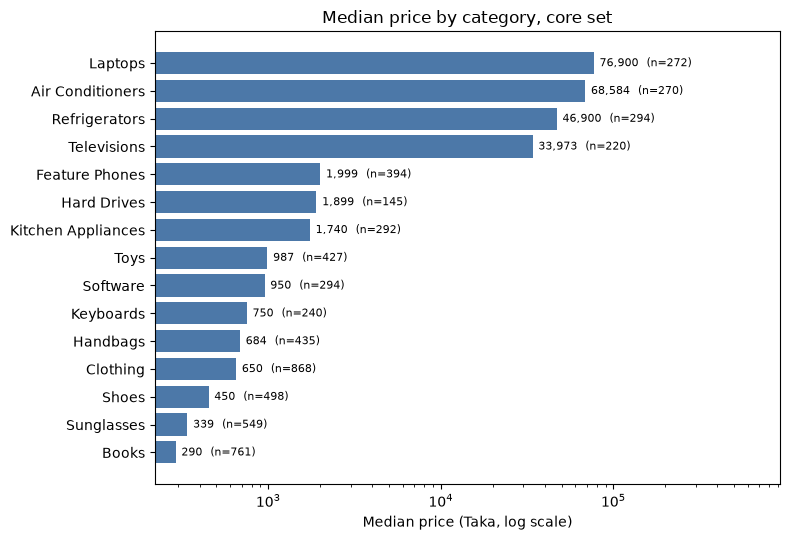

In [9]:
price = core.groupby("category_normalized")["price"].describe(percentiles=[0.25, 0.5, 0.75])
price = price[["count", "25%", "50%", "75%"]]
price.columns = ["n", "p25", "median", "p75"]
price["n"] = price["n"].astype(int)
price = price.sort_values("median", ascending=False)
print(price.round(0).to_string())

fig, ax = plt.subplots(figsize=(8, 5.5))
order = price.index[::-1]
ax.barh(order, price.loc[order, "median"], color="#4C78A8")
ax.set_xscale("log")
ax.set_xlabel("Median price (Taka, log scale)")
for i, cat in enumerate(order):
    ax.text(price.loc[cat, "median"] * 1.08, i,
            f"{price.loc[cat, 'median']:,.0f}  (n={int(price.loc[cat, 'n'])})", va="center", fontsize=8)
ax.set_xlim(right=price["median"].max() * 12)
ax.set_title("Median price by category, core set")
plt.tight_layout()
plt.show()

**What I found:** four big shark categories sit far above everything else: Laptops (**76,900** Taka median), Air Conditioners (**68,584**), Refrigerators (**46,900**) and Televisions (**33,973**). Then there is a big gap down to Feature Phones (**1,999**), and the rest run from Hard Drives (1,899) down to Books (**290**). The spread inside a category is wide too: Televisions go from 25,000 (25th percentile) to 65,242 (75th), and Hard Drives from 760 to 4,250.

**Why it matters:** the top is about 265 times the bottom, so any chart that mixes categories needs a log scale or a per category view. The wide spreads in TVs and Hard Drives mean the median hides size (32-inch TV and a 65-inch TV) and storage tiers (128 GB vs 4 TB), which I did not split further.

## 5. Discount behavior

Two questions per category: how many products are discounted, and how deep is the discount when there is one. Depth is the median among discounted products only. One caveat I cannot remove: the discount is calculated from the original price the seller lists, and I have no way to check if that original price was ever real.

In [10]:
disc = core.groupby("category_normalized").agg(
    n=("price", "size"),
    discounted_pct=("is_discounted", lambda s: s.mean() * 100),
)
d_only = core[core["is_discounted"]].groupby("category_normalized")["discount_perc"]
disc["median_depth"] = d_only.median()
disc["deep_50plus_pct"] = d_only.apply(lambda s: (s >= 50).mean() * 100)
disc = disc.sort_values("discounted_pct", ascending=False)
print(disc.round(1).to_string())

print("\nAcross the whole core set: %.1f%% discounted, median depth %.0f%% among discounted"
      % (core["is_discounted"].mean() * 100, core.loc[core["is_discounted"], "discount_perc"].median()))

                       n  discounted_pct  median_depth  deep_50plus_pct
category_normalized                                                    
Sunglasses           549            99.6          60.0             75.0
Shoes                498            97.6          60.0             78.2
Toys                 427            93.2          49.5             50.0
Handbags             435            92.6          58.0             65.0
Keyboards            240            91.7          29.5             16.8
Books                761            89.6          40.5             39.1
Hard Drives          145            84.1          41.5             41.8
Clothing             868            81.3          45.0             43.6
Kitchen Appliances   292            80.5          30.0             17.0
Feature Phones       394            66.8          20.0              9.9
Laptops              272            64.7           6.0              0.0
Software             294            57.1          42.5          

**What I found:** discounting is the norm. **80.2%** of core products show a discount, with a median depth of **43%**. But it splits in two. Cheap categories discount almost everything, and deeply: Sunglasses **99.6%** discounted (median 60%, and three quarters of those are 50% or more), Shoes **97.6%** (60%), Handbags 92.6% (58%). Big ticket categories discount less and shallowly: Refrigerators **44.2%** discounted with a median depth of only **3.5%**, Laptops 64.7% at 6%, Air Conditioners 47.4% at 17%, Televisions 51.8% at 20%.

**Why it matters:** 50% off is ordinary on a sunglasses listing and almost never seen on a laptop, so one average discount across Daraz would describe neither. Part of the cheap category pattern may come from inflated list prices instead of real savings, and this data cannot tell the two apart. So I call it listed discount, not savings.

## 6. How much rating data is there per category?

Before showing any category rating, I need a minimum number of rated products. With a handful of ratings, one 5.0 decides the average. I use the unflagged set here (accessories included), because a rating describes a listing's feedback, not how much the product costs. The 95% interval in the table shows how far the average could move from chance alone.

In [11]:
MIN_RATED = 20

rated = clean[clean["has_reviews"]]
cov = clean.groupby("category_normalized").agg(products=("price", "size"))
g = rated.groupby("category_normalized")["stars"]
cov["rated_n"] = g.size()
cov["rated_n"] = cov["rated_n"].fillna(0).astype(int)
cov["rated_pct"] = cov["rated_n"] / cov["products"] * 100
cov["mean_stars"] = g.mean()
cov["ci95"] = 1.96 * g.std() / np.sqrt(g.size())
cov["enough_data"] = cov["rated_n"] >= MIN_RATED
cov = cov.sort_values("rated_n", ascending=False)
print(cov.round(2).to_string())

print("\nCategories with at least 20 rated products:", int((cov["rated_n"] >= 20).sum()))
print("Categories with at least 30 rated products:", int((cov["rated_n"] >= 30).sum()))
print("Rated products overall (unflagged): %d of %d (%.1f%%)" % (len(rated), len(clean), len(rated) / len(clean) * 100))

                     products  rated_n  rated_pct  mean_stars  ci95  enough_data
category_normalized                                                             
Toys                      427      261      61.12        4.60  0.08         True
Keyboards                 368       95      25.82        4.49  0.13         True
Sunglasses                549       45       8.20        4.73  0.11         True
Hard Drives               179       29      16.20        4.59  0.25         True
Books                     761       22       2.89        4.77  0.09         True
Kitchen Appliances        443       20       4.51        4.41  0.44         True
Clothing                  868       16       1.84        4.44  0.24        False
Handbags                  435       14       3.22        4.69  0.21        False
Feature Phones            394       14       3.55        4.22  0.39        False
Software                  294       10       3.40        4.91  0.08        False
Air Conditioners          42

**What I found:** only **546 of 6,602** unflagged products (**8.3%**) have a real rating, and they are concentrated. Toys has 261 and Keyboards 95, which together are 65% of all rated products. Laptops has 0, Refrigerators 2 and Shoes 3. I set the minimum at **20 rated products** per category, which keeps six categories: Toys, Keyboards, Sunglasses, Hard Drives, Books and Kitchen Appliances. At a minimum of 30, only Toys, Keyboards and Sunglasses would remain. Average stars in the six sit between 4.41 and 4.77 and most of the intervals overlap.

**Why it matters:** 20 is a compromise. It leaves enough bars to read on page 2, but Kitchen Appliances (20 products, plus or minus 0.44 stars) and Hard Drives (29, plus or minus 0.25) are still shaky, which is why n sits next to every bar. I would not rank categories by their average rating, because the differences are mostly inside the noise. The more honest headline is that rating data is thin: roughly 1 product in 12 has one.

## 7. Rating vs review count: can I trust a 5.0?

A product with 1 review and 5 stars is not the same as one with 200 reviews and 4.7. I split rated products into review count bands and look at how many sit at exactly 5.0 stars in each band.

           n  mean_stars  median_stars  five_star_pct
reviews                                              
1-2      146        4.52           5.0          73.97
3-9      179        4.67           5.0          53.07
10-49    146        4.61           4.7          23.97
50+       75        4.53           4.6           0.00

Products rated 4.8 or higher: 295
...of which have fewer than 10 reviews: 220 (75%)
Mean stars, products with 10+ reviews: 4.58 (n=221)
Mean stars, products with under 10 reviews: 4.60 (n=325)


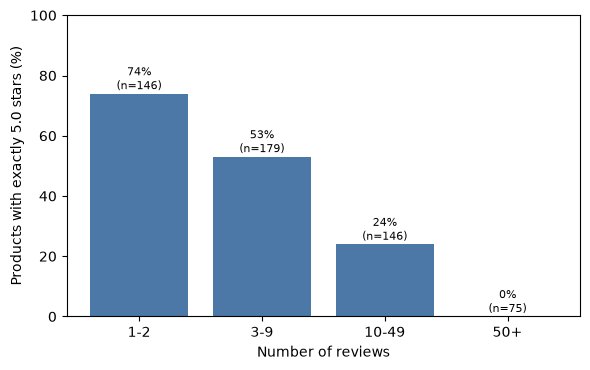

In [12]:
bands = pd.cut(rated["reviews"], bins=[0, 2, 9, 49, 10**7], labels=["1-2", "3-9", "10-49", "50+"])
trust = rated.groupby(bands, observed=True)["stars"].agg(
    n="size", mean_stars="mean", median_stars="median",
    five_star_pct=lambda s: (s == 5).mean() * 100,
)
print(trust.round(2).to_string())

high = rated[rated["stars"] >= 4.8]
thin = high[high["reviews"] < 10]
print("\nProducts rated 4.8 or higher:", len(high))
print("...of which have fewer than 10 reviews:", len(thin), f"({len(thin)/len(high)*100:.0f}%)")
print("Mean stars, products with 10+ reviews: %.2f (n=%d)" % (rated.loc[rated["reviews"] >= 10, "stars"].mean(), (rated["reviews"] >= 10).sum()))
print("Mean stars, products with under 10 reviews: %.2f (n=%d)" % (rated.loc[rated["reviews"] < 10, "stars"].mean(), (rated["reviews"] < 10).sum()))

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.bar(trust.index.astype(str), trust["five_star_pct"], color="#4C78A8")
for i, (pct, n) in enumerate(zip(trust["five_star_pct"], trust["n"])):
    ax.text(i, pct + 1.5, f"{pct:.0f}%\n(n={int(n)})", ha="center", fontsize=8)
ax.set_ylim(0, 100)
ax.set_xlabel("Number of reviews")
ax.set_ylabel("Products with exactly 5.0 stars (%)")
plt.tight_layout()
plt.show()

**What I found:** the share of perfect 5.0 scores falls as review counts grow. **74%** of products with 1 or 2 reviews have exactly 5.0 stars, **53%** at 3 to 9 reviews, **24%** at 10 to 49, and **0%** at 50 or more. Of the 295 products rated 4.8 or higher, **220 (75%)** have fewer than 10 reviews. The overall average hardly moves though: 4.58 stars for products with 10 or more reviews (n=221) against 4.60 for those with fewer (n=325).

**Why it matters:** the average rating is stable, but the top of the ranking is not. The best looking scores belong to products with a handful of reviews, which are the least reliable. So a high rating with a low review count is flagged as less credible, and the value ranking needs a minimum review count. I use 10.

## 8. Does a deeper discount mean a lower rating?

The idea to test: heavy discounts might signal clearance or poor quality, which would show up as lower stars. I tried two views, as planned. A scatter first, then bands of discount depth with the average stars and the count in each band. I also repeat the bands for products with 10 or more reviews, to keep out the thin ratings from the last section.

All rated products:
                 n  mean_stars  median_stars
discount_perc                               
0               44        4.54           4.8
1-20            88        4.53           4.8
21-40          141        4.47           4.6
41-60          207        4.71           5.0
61+             66        4.61           4.9

Products with 10+ reviews:
                n  mean_stars  median_stars
discount_perc                              
0              15        4.47          4.50
1-20           37        4.54          4.60
21-40          57        4.51          4.50
41-60          84        4.64          4.70
61+            28        4.63          4.65

Spearman correlation, discount vs stars: all rated 0.19 (n=546) | 10+ reviews 0.24 (n=221)
  within Toys: 0.26 (n=261)
  within Keyboards: -0.09 (n=95)


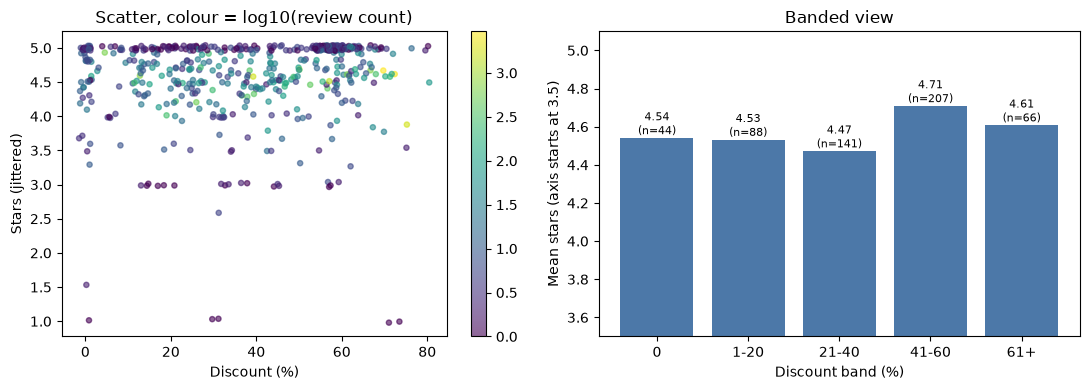

In [13]:
dbands = pd.cut(rated["discount_perc"], bins=[-1, 0, 20, 40, 60, 100], labels=["0", "1-20", "21-40", "41-60", "61+"])
band_all = rated.groupby(dbands, observed=True)["stars"].agg(n="size", mean_stars="mean", median_stars="median")
r10 = rated[rated["reviews"] >= 10]
d10 = pd.cut(r10["discount_perc"], bins=[-1, 0, 20, 40, 60, 100], labels=["0", "1-20", "21-40", "41-60", "61+"])
band_10 = r10.groupby(d10, observed=True)["stars"].agg(n="size", mean_stars="mean", median_stars="median")
print("All rated products:")
print(band_all.round(2).to_string())
print("\nProducts with 10+ reviews:")
print(band_10.round(2).to_string())

rho_all = rated[["discount_perc", "stars"]].corr(method="spearman").iloc[0, 1]
rho_10 = r10[["discount_perc", "stars"]].corr(method="spearman").iloc[0, 1]
print("\nSpearman correlation, discount vs stars: all rated %.2f (n=%d) | 10+ reviews %.2f (n=%d)" % (rho_all, len(rated), rho_10, len(r10)))
for cat in ["Toys", "Keyboards"]:
    x = rated[rated["category_normalized"] == cat]
    print("  within %s: %.2f (n=%d)" % (cat, x[["discount_perc", "stars"]].corr(method="spearman").iloc[0, 1], len(x)))

rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sc = axes[0].scatter(
    rated["discount_perc"] + rng.uniform(-1.5, 1.5, len(rated)),
    rated["stars"] + rng.uniform(-0.04, 0.04, len(rated)),
    c=np.log10(rated["reviews"]), cmap="viridis", s=14, alpha=0.6)
axes[0].set_xlabel("Discount (%)")
axes[0].set_ylabel("Stars (jittered)")
axes[0].set_title("Scatter, colour = log10(review count)")
fig.colorbar(sc, ax=axes[0])
axes[1].bar(band_all.index.astype(str), band_all["mean_stars"], color="#4C78A8")
for i, (m, n) in enumerate(zip(band_all["mean_stars"], band_all["n"])):
    axes[1].text(i, m + 0.02, f"{m:.2f}\n(n={int(n)})", ha="center", fontsize=8)
axes[1].set_ylim(3.5, 5.1)
axes[1].set_xlabel("Discount band (%)")
axes[1].set_ylabel("Mean stars (axis starts at 3.5)")
axes[1].set_title("Banded view")
plt.tight_layout()
plt.show()

**What I found:** the scatter is hard to read. Most points pile up between 4 and 5 stars because stars come in near whole numbers, and the colour mainly shows that low review count points sit at 5.0. The banded view is clearer. Average stars by discount band are 4.54 (no discount), 4.53, 4.47, 4.71 and 4.61 (61% and over), with 44 to 207 products per band. Limiting to products with 10 or more reviews gives the same shape (4.47 to 4.64). The Spearman correlation is weak and positive: **0.19** for all rated products and **0.24** for those with 10 or more reviews (n=221).

**Why it matters:** I found no sign that deep discounts mean lower ratings. If anything, products discounted 41% or more rate slightly higher, by at most 0.24 stars, and not in a steady way. Much of that small link is a Toys effect: Toys are 48% of rated products and show 0.26 inside the category, while Keyboards show -0.09. So the clearance means lower quality idea is not supported here, but I would not claim the opposite either. The honest conclusion is that discount depth and rating are largely unrelated in this data. 

## 9. Value ranking

The goal is to surface the best rated products for the price within each category. I only rank products with at least 10 reviews, otherwise a single 5.0 review would win. Within each category, every eligible product gets a percentile rank for stars, for review count and for price (cheaper is better), and the score is 40% stars, 20% review count, 40% price. The weights are my judgment call, not a law. A category needs at least 10 eligible products before I show a ranking.

In [14]:
MIN_REVIEWS = 10
MIN_ELIGIBLE = 10
W_STARS, W_REVIEWS, W_PRICE = 0.4, 0.2, 0.4

elig = core[core["has_reviews"] & (core["reviews"] >= MIN_REVIEWS)].copy()
grp = elig.groupby("category_normalized")
elig["r_stars"] = grp["stars"].rank(pct=True)
elig["r_reviews"] = grp["reviews"].rank(pct=True)
elig["r_price"] = 1 - grp["price"].rank(pct=True)
elig["value_score"] = W_STARS * elig["r_stars"] + W_REVIEWS * elig["r_reviews"] + W_PRICE * elig["r_price"]

counts = elig.groupby("category_normalized").size().sort_values(ascending=False)
print("Eligible products per category:", counts.to_dict())

ranked = elig[elig["category_normalized"].isin(counts[counts >= MIN_ELIGIBLE].index)]
top = (ranked.sort_values(["category_normalized", "value_score"], ascending=[True, False])
             .groupby("category_normalized").head(3))
top = top[["category_normalized", "name", "price", "stars", "reviews", "value_score"]].copy()
top["name"] = top["name"].str[:48]
print()
print(top.round(2).to_string(index=False))

Eligible products per category: {'Toys': 91, 'Keyboards': 35, 'Sunglasses': 17, 'Books': 12, 'Clothing': 11, 'Hard Drives': 11, 'Handbags': 9, 'Feature Phones': 5, 'Air Conditioners': 5, 'Software': 4, 'Televisions': 3, 'Kitchen Appliances': 2, 'Shoes': 1}

category_normalized                                             name  price  stars  reviews  value_score
              Books English Grammar In Use By Raymond Murphy Newspri   96.0    4.6     78.0         0.70
              Books  IELTS Writing Task 2 Samples by Rachel Mitchell  239.0    5.0     14.0         0.67
              Books Early Learning kids জ্ঞানবাক্স-6 pcs Book Multic  219.0    4.6     58.0         0.60
           Clothing Polo Shirt For Men Summer Cotton Short Sleeve Ca  247.0    4.6    299.0         0.80
           Clothing Stylish Polo Shirt For Men Summer Premium Cotton  298.0    4.6    199.0         0.71
           Clothing Premium Combo Pack Polo Shirt For Men Summer Cot  480.0    4.7    129.0         0.62
       

**What I found:** only six categories have 10 or more eligible products (at least 10 reviews): Toys (91), Keyboards (35), Sunglasses (17), Books (12), Clothing (11) and Hard Drives (11). Many top picks look sensible, such as the Logitech K120 keyboard at 750 Taka with 4.9 stars and 618 reviews, or an English grammar book at 96 Taka with 4.6 stars and 78 reviews. Some do not: the top Hard Drives results include an HDD cage and an external drive case, and one Toys result is a lithium battery with a charging cable.

**Why it matters:** the score does what I designed it to do, but it is only as good as the category assignment, and accessories filed under the main leaf slip through. So I treat the value ranking as a demonstration of the method on categories with enough reviews, not as a shopping guide. The 40/20/40 weights are my judgment call, which is why I state them. The big ticket categories do not appear at all, because almost none of their products have 10 reviews.

## 10. Brand: is there enough to say anything?

The requirements doc promised price by brand, but the page 2 mockup has no brand chart. Before deciding, I check how often a brand is actually filled in. `No Brand` is Daraz's placeholder, so it counts as empty.

In [15]:
brand = core["brand"].fillna("No Brand").str.strip()
core["has_brand"] = ~brand.str.lower().isin(["no brand", "nobrand", "none", "n/a", ""])

fill = core.groupby("category_normalized")["has_brand"].agg(brand_filled_pct=lambda s: s.mean() * 100, n="size")
print("Overall brand filled: %.1f%%" % (core["has_brand"].mean() * 100))
print(fill.sort_values("brand_filled_pct", ascending=False).round(1).to_string())

big4 = ["Laptops", "Televisions", "Refrigerators", "Air Conditioners"]
b4 = core[core["category_normalized"].isin(big4) & core["has_brand"]].copy()
b4["brand_key"] = b4["brand"].str.strip().str.lower()
# keep the most common spelling of each brand (so "HP" stays "HP", and "walton" joins "Walton")
spelling = b4.groupby("brand_key")["brand"].agg(lambda s: s.str.strip().value_counts().idxmax())
def tidy(name):
    # all lowercase or long all caps names become Title Case; short ones like HP or LG stay as they are
    return name.title() if (name.islower() or (name.isupper() and len(name) > 3)) else name
b4["brand_name"] = b4["brand_key"].map(spelling.map(tidy))
bp =b4.groupby(["category_normalized", "brand_name"])["price"].agg(n="size", median_price="median")
print("\nMedian price by brand, big ticket categories, brands with 15+ products:")
print(bp[bp["n"] >= 15].round(0).sort_values(["category_normalized", "median_price"], ascending=[True, False]).to_string())

Overall brand filled: 23.9%
                     brand_filled_pct    n
category_normalized                       
Refrigerators                    94.6  294
Air Conditioners                 88.1  270
Laptops                          75.0  272
Televisions                      69.1  220
Keyboards                        29.2  240
Kitchen Appliances               22.9  292
Software                         19.0  294
Clothing                         18.8  868
Feature Phones                   15.7  394
Hard Drives                      13.1  145
Sunglasses                       11.8  549
Toys                              8.9  427
Handbags                          1.4  435
Books                             0.9  761
Shoes                             0.4  498

Median price by brand, big ticket categories, brands with 15+ products:
                                 n  median_price
category_normalized brand_name                  
Air Conditioners    Hisense     16       75900.0
                    W

**What I found:** a brand is filled in for only **23.9%** of core products overall, and it splits sharply. Refrigerators (**94.6%**), Air Conditioners (**88.1%**), Laptops (**75.0%**) and Televisions (**69.1%**) are well covered. Keyboards are at 29%, and every other category is under 23%, down to Books at 0.9% and Shoes at 0.4%. Within the four covered categories, brands separate clearly on price. Haier refrigerators have a median of 75,900 Taka against 44,500 for Minister, and Sony TVs 104,000 against 30,490 for Walton.

**Why it matters:** price by brand only means something in those four categories, so the price by brand analysis planned in the project requirement cannot be done across the whole dataset. That section assumed brand would be filled everywhere. The page 2 mockup has no brand chart, so I would leave it out of Power BI and keep this table in the notebook as the brand finding.

## 11. Numbers for Power BI page 2

The headline numbers the page needs, taken from the work above, so the dashboard and this notebook say the same thing.

In [16]:
print("All rows in clean_products:", len(df))
print("Flagged rows excluded:", int(df["is_contamination_flagged"].sum()))
print("Accessory rows excluded from price and discount stats:", int(clean["is_accessory"].sum()))
print("Core set used for price and discount:", len(core))
print()
print("Unflagged products with a real rating: %d of %d (%.1f%%)" % (len(rated), len(clean), len(rated) / len(clean) * 100))
print("Rated products with 10+ reviews:", int((rated["reviews"] >= 10).sum()))
print("Products rated 4.8+ with under 10 reviews:", len(thin))
print("Categories with at least %d rated products: %s" % (MIN_RATED, cov.index[cov["enough_data"]].tolist()))
print("Categories with a value ranking:", counts[counts >= MIN_ELIGIBLE].index.tolist())

All rows in clean_products: 8252
Flagged rows excluded: 1650
Accessory rows excluded from price and discount stats: 643
Core set used for price and discount: 5959

Unflagged products with a real rating: 546 of 6602 (8.3%)
Rated products with 10+ reviews: 221
Products rated 4.8+ with under 10 reviews: 220
Categories with at least 20 rated products: ['Toys', 'Keyboards', 'Sunglasses', 'Hard Drives', 'Books', 'Kitchen Appliances']
Categories with a value ranking: ['Toys', 'Keyboards', 'Sunglasses', 'Books', 'Clothing', 'Hard Drives']
